# QA_max_cut_lib · быстрый старт

Версия **0.1.0a1**, первый рабочий CPU-этап. За один небольшой эксперимент мы создадим взвешенный граф, вычислим точный ориентир, запустим QAOA, получим результат, построим графики и сохраним данные.

Используется энергия $E=-C$: **меньшая энергия лучше**. В этой версии реализованы ExactCPU и QAOACPU. LS, RQAOA, GPU, Laboratory, общий бенчмарк и контрольные точки ещё предстоит перенести; этот ноутбук не имитирует их работу.

Запускайте ячейки сверху вниз. Все расчёты малы и работают без NVIDIA. При повторном выполнении создаётся новое явно названное место экспорта; научный seed остаётся тем же.

## 1. Установка и импорты

В терминале из корня распакованного проекта:

```bash
python -m pip install -e ".[cpu,notebooks]"
python -m jupyter lab notebooks/01_quickstart.ipynb
```

Выберите ядро того же Python-окружения. Системный LaTeX для этого примера не требуется: режим MathText указан явно, шрифт — Computer Modern.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
import json
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
import QA_max_cut_lib as qa
from QA_max_cut_lib import GraphFactory, SolverFactory, ExactCPU
from QA_max_cut_lib import tools

root = Path.cwd()
if not (root / 'configs').is_dir():
    root = root.parent
assert (root / 'configs').is_dir(), 'Open the notebook from the project or notebooks folder.'
plot_style = {'text_engine': 'mathtext', 'figsize': [10, 6]}
export_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
output_dir = root / 'notebooks' / '_outputs' / ('quickstart_' + export_id)
print('QA_max_cut_lib', qa.__version__)

No event loop hook running.
QA_max_cut_lib 0.1.0a1


## 2. Граф из отдельного JSON-рецепта

Рецепт задаёт полный граф из семи вершин, исходные номера с пропусками, дискретные веса $\{-1,+1\}$ и независимые seeds топологии и весов. Даже единичный вес должен задаваться явно. Граф можно редактировать после создания.

Nodes: (10, 20, 30, 50, 80, 130, 210)
Edges: 21


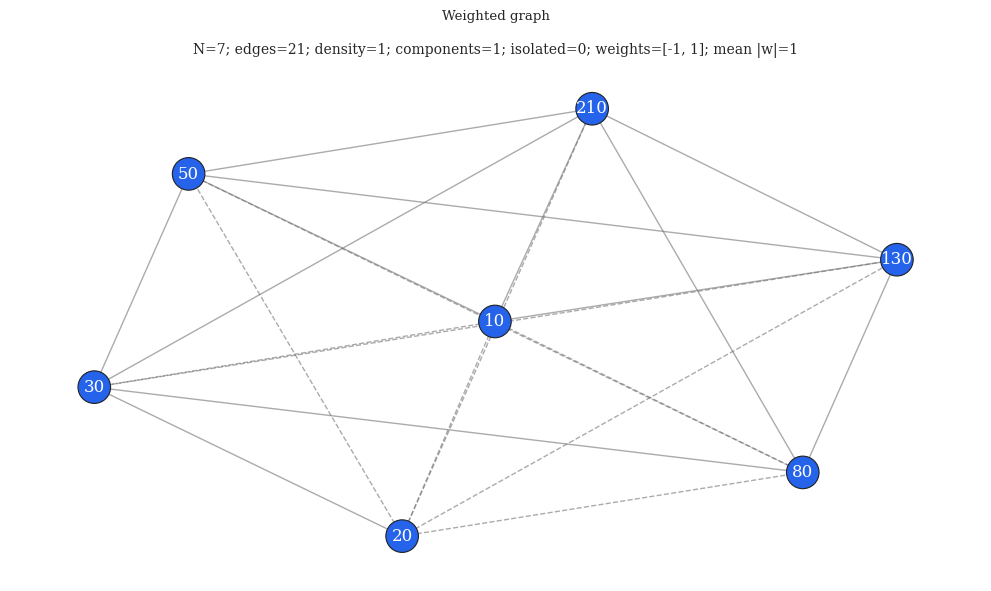

In [2]:
graph_config = tools.load_json(root / 'configs/graphs/complete_signed_7.json')
graph = GraphFactory.from_recipe(graph_config)
print('Nodes:', graph.nodes)
print('Edges:', len(graph.edges))
figure = tools.plot_graph_info(graph, {'style': plot_style, 'graph': {'weight_labels': False}})
display(figure)
plt.close(figure)

## 3. Точный ориентир и независимый QAOA

ExactCPU полностью перебирает спиновые назначения с учётом симметрии глобальной инверсии. На семи вершинах это быстро. Он нужен для проверки качества, а не для замены QAOA.

QAOACPU читает отдельный JSON: p=1, ADAM, точная оценка среднего, 30 шагов, затем 256 конечных шотов с выбором лучшего решения. Конечные шоты входят в общий бюджет. Во время точного обучения шоты не расходуются.

In [3]:
reference = ExactCPU({'output': {'color': 'never'}})
reference.solve(graph, report=1)

solver_config = tools.load_json(root / 'configs/solvers/qaoa_cpu.json')
solver_config['output']['color'] = 'never'
algorithm = SolverFactory.from_config(solver_config)
solution = algorithm.solve(graph, report=1, logs=0)
quality = tools.quality_score(algorithm.cut_value, reference.cut_value, reference.worst_cut_value)
print('Exact E:', reference.solution_energy)
print('QAOA solution E:', algorithm.solution_energy)
print('QAOA expected E:', round(algorithm.expected_energy, 6))
print('Quality in exact min/max range:', round(quality, 6))
print('Shot counters:', algorithm.resources)
assert set(solution) == set(graph.nodes)
assert algorithm.resources['shots_used'] <= solver_config['limits']['shots_total']

QA_max_cut_lib | exact_cpu | completed
Cut: 6   Energy: -6   Time: 0.0010 s
Resources: {"num_stages": 2, "num_treads": 1, "shots_used": 0, "states_evaluated": 128}
QA_max_cut_lib | qaoa_cpu | completed
Cut: 6   Energy: -6   Time: 0.0282 s
Resources: {"num_stages": 31, "num_treads": 1, "objective_evaluations": 150, "optimizer_steps": 30, "readout_shots": 256, "shots_used": 256, "training_shots": 0}
Exact E: -6.0
QAOA solution E: -6.0
QAOA expected E: -3.857348
Quality in exact min/max range: 1.0
Shot counters: {'shots_used': 256, 'training_shots': 0, 'readout_shots': 256, 'objective_evaluations': 150, 'optimizer_steps': 30, 'num_stages': 31, 'num_treads': 1}


## 4. Доступ к результату

`solve()` вернул словарь `исходная_вершина: ±1`. `algorithm.result` содержит весь последний запуск в JSON-совместимом представлении. `algorithm.attribute` возвращает нативные данные; например, углы — NumPy-массив. `last_run` фиксирует этот запуск независимо от будущих запусков солвера.

In [4]:
record = algorithm.last_run
json_result = algorithm.result
assert json_result['solution_energy'] == algorithm.solution_energy
json_text = json.dumps(json_result, ensure_ascii=False, allow_nan=False)
print('Solution:', solution)
print('Angles [gamma_0, beta_0]:', algorithm.optimal_angles)
print('Complete JSON size, bytes:', len(json_text.encode('utf-8')))
print('Run ID:', record.run_id)

Solution: {10: -1, 20: -1, 30: 1, 50: -1, 80: -1, 130: 1, 210: -1}
Angles [gamma_0, beta_0]: [ 0.36611879 -0.4124642 ]
Complete JSON size, bytes: 13322
Run ID: c80fd395-af05-4d4c-8749-10e5b83c3b87


## 5. Инструменты получают сам солвер

Накопление вероятностей и истории было включено **до** `solve()`. Инструменты не запускают обучение заново. Для выбранного критерия Mean Cut функция потерь равна ожиданию энергии. Вероятностная диаграмма показывает только top-12 состояний с их исходными вероятностями; остаток массы указан в заголовке.

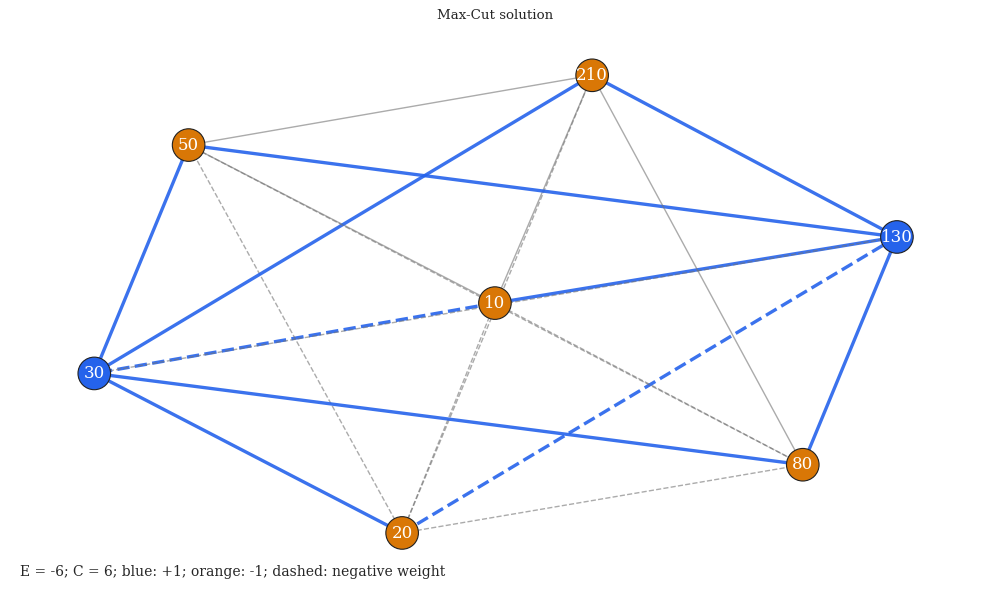

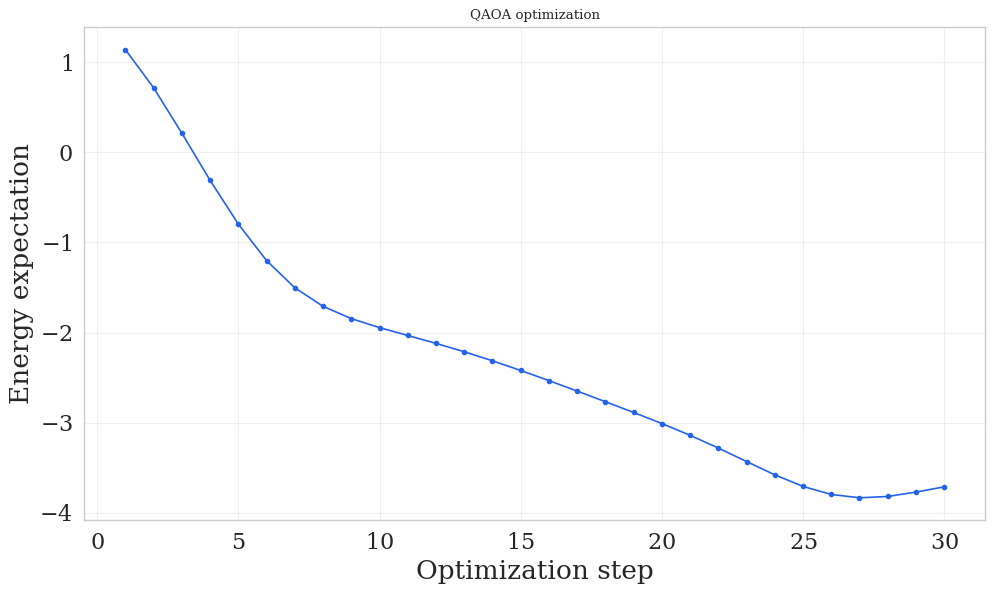

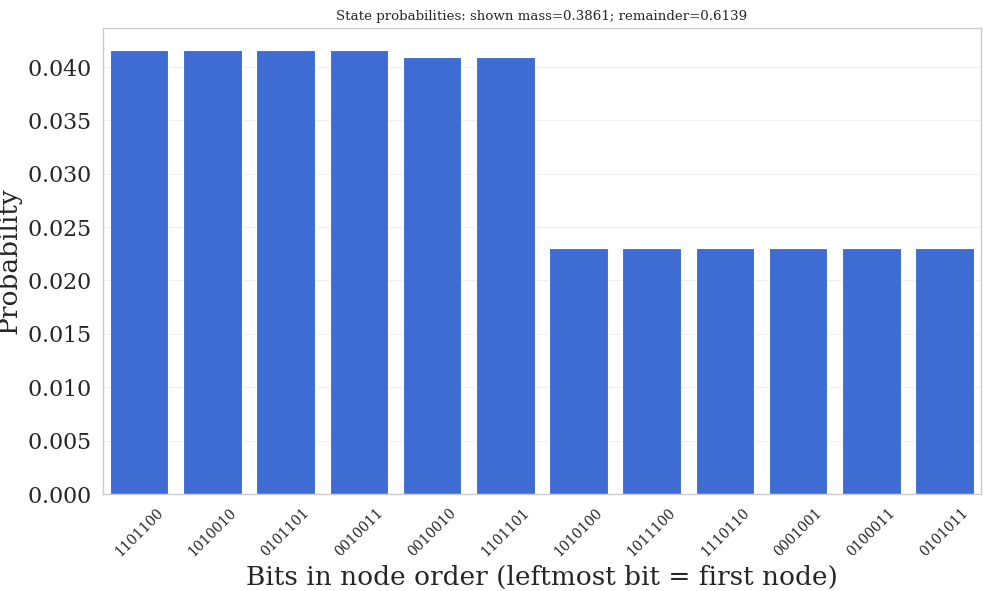

In [5]:
figure = tools.plot_graph_solution(algorithm, config={
    'style': plot_style, 'graph': {'weight_labels': False},
})
display(figure)
plt.close(figure)

figure = tools.plot_optimization(algorithm, {'style': plot_style})
display(figure)
plt.close(figure)

figure = tools.plot_probabilities(algorithm, {
    'style': plot_style, 'selection': {'top_k': 12},
})
display(figure)
plt.close(figure)

## 6. Выборочный JSON и исходный массив

Без `save` файлы автоматически не создавались. Сейчас явно сохраним решение, энергию и углы в JSON, вероятности — отдельным `.npy`. Поля конфигурации, снимок графа, даты, время, ресурсы и отчёт сохраняются обязательно. `savedir=True` создаёт папку с именем `filename`.

In [6]:
save_config = {
    'path': str(output_dir), 'filename': 'qaoa_run',
    'atts': ['solution', 'cut_value', 'solution_energy', 'expected_energy', 'optimal_angles'],
    'save_original_data': ['probabilities'],
    'makedir': True, 'savedir': True,
}
saved = tools.save_result(algorithm, save_config)
restored = tools.load_result(saved.primary, load_original_data=True)
assert restored.solution == solution
assert restored.probabilities.shape == algorithm.probabilities.shape
print('Saved files:', [path.name for path in saved.files])

Saved files: ['qaoa_run_probabilities.npy', 'qaoa_run.json']


## 7. График из сохранённых данных

Теперь вход инструмента — загруженная запись. `metadata=True` добавляет видимую подпись с происхождением. Для самостоятельного JSON результата инструмента можно дополнительно указать `atts` в его `save`.

Figure: probabilities.png


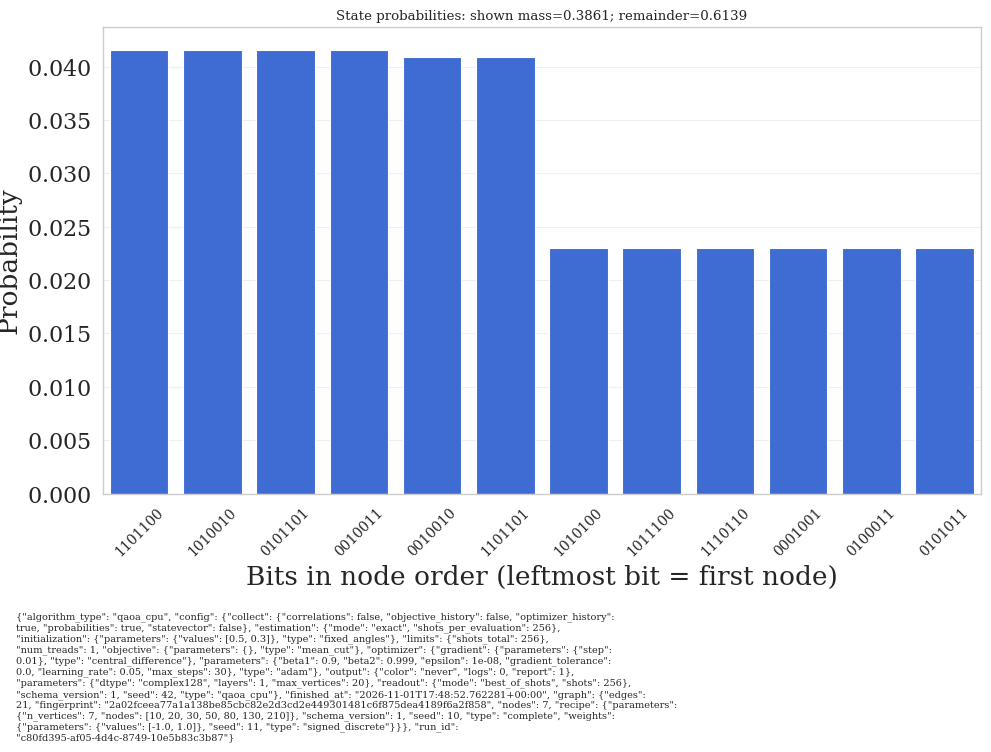

In [7]:
figure = tools.plot_probabilities(restored, {
    'style': plot_style, 'selection': {'top_k': 12},
    'save': {
        'path': str(output_dir), 'filename': 'probabilities',
        'format': 'png', 'DPI': 250, 'metadata': True,
        'makedir': True, 'savedir': True,
    },
})
display(figure)
print('Figure:', figure.qa_saved_files.primary.name)
plt.close(figure)

## 8. Защита и повторный запуск

Попытка повторить экспорт с тем же именем должна завершиться ошибкой. Повторный расчёт с тем же seed даёт то же научное решение; идентификатор и время запуска будут новыми. Старый `record` остаётся доступным. Для нового имени экспорта заново выполните первую ячейку с `export_id`.

In [8]:
try:
    tools.save_result(algorithm, save_config)
except FileExistsError:
    print('Expected: the previous export is protected.')
else:
    raise AssertionError('A repeated export must not overwrite files.')

old_run_id = record.run_id
new_solution = algorithm.solve(graph, report=0, logs=0)
assert new_solution == solution
assert algorithm.run_id != old_run_id
assert record.run_id == old_run_id
print('Fresh run, same seed, same solution; the old record is unchanged.')

Expected: the previous export is protected.
Fresh run, same seed, same solution; the old record is unchanged.


## Дальше

В `02_current_api_guide.ipynb` разобраны шотовое обучение, все пять критериев, многослойный QAOA, карты p=1, корреляции и остальные реализованные инструменты. Поля конфигурации и результаты описаны в `docs/API.md`, физика — в `docs/MATHEMATICS.md`, будущий объём переноса — в `docs/MIGRATION_STATUS.md`.